# PIROPO Room B (conventional camera): data exploration

Exploration of the [PIROPO database](https://www.gti.ssr.upm.es/data/piropodatabase) subset in `data/roomb_piropo`, with an eye on battery-free (WISP) person detection:

1. **Inventory**: sequences, frame counts, which ones are annotated, frame rate.
2. **Annotations**: format, person-present fraction, how many people, where they stand.
3. **Images**: sample frames with annotations, brightness over time.
4. **What the WISP would see**: grayscale 160×120 (the resolution used in the Colab notebook) and thumbnails at EPC-sized byte budgets.
5. **Room-specific baselines**: how far a fixed background model plus a handful of pixels gets, as a first check on the "learn an encoding that only fits this room" idea.
6. **Optional export** of a compact `.npz` for training.

Only the `conv_2B` (conventional perspective camera) sequences are extracted; `omni_1B.zip` (omnidirectional camera) is still zipped.

## 1. Setup and inventory

In [1]:
import re, time
from datetime import datetime
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

ROOT = Path('..') / 'data' / 'roomb_piropo' / 'Room B' / 'conv_2B' / 'conv_2B'
ANN_DIR = ROOT / 'Ground_Truth_Annotations'
H, W = 120, 160          # WISP-camera resolution used in the Colab experiments
assert ROOT.exists(), f'data not found at {ROOT.resolve()}'

def frame_time(fn):
    # file names are capture timestamps, e.g. 2015-11-13T12-14-47.255Z.jpg
    return datetime.strptime(fn.stem, '%Y-%m-%dT%H-%M-%S.%fZ')

seqs = {}
for d in sorted(ROOT.iterdir(), key=lambda p: [int(t) if t.isdigit() else t for t in re.split(r'(\d+)', p.name)]):
    if not d.is_dir() or d == ANN_DIR:
        continue
    name = d.name.replace('conv2B_', '')
    files = sorted(d.glob('*.jpg'))
    ann = ANN_DIR / f'groundTruth_{d.name}.csv'
    seqs[name] = dict(dir=d, files=files, ann=ann if ann.exists() else None,
                      times=np.array([frame_time(f).timestamp() for f in files]))

with Image.open(seqs['training']['files'][0]) as im:
    FULL_W, FULL_H = im.size
    print(f'native frame size: {FULL_W}x{FULL_H} {im.mode}\n')

print(f"{'sequence':<16}{'frames':>7}{'annotated':>11}{'duration s':>12}{'median fps':>12}")
for name, s in seqs.items():
    dt = np.diff(s['times'])
    print(f"{name:<16}{len(s['files']):>7}{'yes' if s['ann'] else '-':>11}{s['times'][-1] - s['times'][0]:>12.1f}{1 / np.median(dt):>12.1f}")
print(f"{'total':<16}{sum(len(s['files']) for s in seqs.values()):>7}")

native frame size: 704x576 RGB

sequence         frames  annotated  duration s  median fps
test1               350        yes        69.4         5.9
test2               140        yes        38.8         4.3
test3               275        yes        52.4         6.0
test4               838          -       180.5         5.5
test6               349          -       102.6         4.1
test7               389          -       110.5         4.2
test8               277          -        70.6         4.3
test9               220          -        69.0         4.3
test10              222          -        76.9         4.0
training           3975        yes       603.9         6.3
training_bg          69          -        22.4         4.2
training_illum      128          -        34.2         4.8
training_seats     2100        yes       521.5         4.4
total              9332


Sequence names hint at their content (from the PIROPO description and the `.info` files): `training` is people walking around the room, `training_seats` people sitting, `training_bg` the empty room, `training_illum` illumination changes, and `test3` ("personNoTraining") a person who does not appear in training. Only `training`, `training_seats` and `test1`–`test3` have ground truth.

Frames arrive at only ~4–6 fps (median), irregularly, so consecutive frames are strongly correlated. Splits should be **by sequence** (or contiguous time blocks), never random frames.

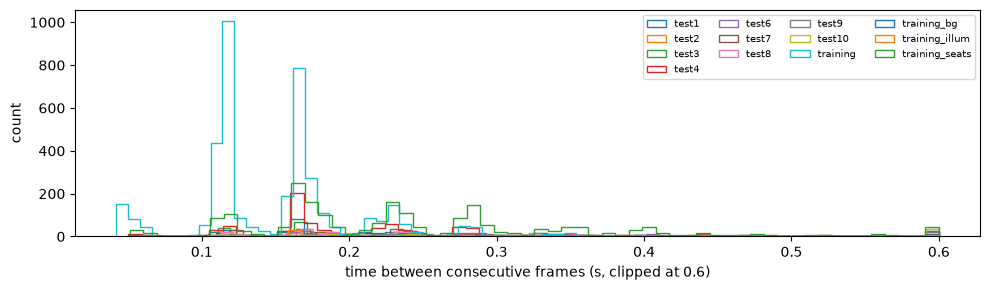

In [2]:
fig, ax = plt.subplots(figsize=(10, 3))
for name, s in seqs.items():
    dt = np.diff(s['times'])
    ax.hist(np.clip(dt, 0, 0.6), bins=60, histtype='step', label=name)
ax.set_xlabel('time between consecutive frames (s, clipped at 0.6)'); ax.set_ylabel('count')
ax.legend(ncol=4, fontsize=7); plt.tight_layout(); plt.show()

## 2. Annotations

Each CSV row is `frame_index, x1, y1[, x2, y2, ...]`: one 1-based row per image (in timestamp order) and one `(x, y)` point per person (on the head) in native 704×576 pixel coordinates. `(0, 0)` means no person in that slot. Below, the row count is checked against the image count, and the `.info` files (ViPER frame lists) are checked against the sorted file order.

In [3]:
for name, s in seqs.items():
    if s['ann'] is None:
        continue
    raw = np.loadtxt(s['ann'], delimiter=',', dtype=int, ndmin=2)
    assert len(raw) == len(s['files']), (name, len(raw), len(s['files']))
    assert (raw[:, 0] == np.arange(1, len(raw) + 1)).all(), name
    pts = raw[:, 1:].reshape(len(raw), -1, 2)                 # frames x slots x (x, y)
    present = (pts != 0).any(-1)                              # frames x slots
    s['points'] = [p[m] for p, m in zip(pts, present)]        # per frame: array of (x, y) for each person
    s['n_people'] = present.sum(1)
    s['label'] = (s['n_people'] > 0).astype(np.uint8)

for info in ROOT.glob('*/*.info'):
    listed = [l.strip() for l in info.read_text().splitlines()[2:] if l.strip()]
    on_disk = [f.name for f in sorted(info.parent.glob('*.jpg'))]
    print(f'{info.parent.name}/{info.name}: frame list matches sorted files: {listed == on_disk}')

print(f"\n{'sequence':<16}{'frames':>7}{'person %':>10}{'max people':>12}{'label switches':>16}")
for name, s in seqs.items():
    if 'label' in s:
        y = s['label']
        print(f"{name:<16}{len(y):>7}{100 * y.mean():>10.1f}{s['n_people'].max():>12}{int(np.abs(np.diff(y.astype(int))).sum()):>16}")

conv2B_test1/salaProjConv1_test1.info: frame list matches sorted files: True
conv2B_test2/salaProjConv1_test4.info: frame list matches sorted files: True
conv2B_test3/salaProjConv1_test_personNoTraining.info: frame list matches sorted files: True

sequence         frames  person %  max people  label switches
test1               350      58.3           1              16
test2               140      80.7           2               6
test3               275      66.9           1               8
training           3975      74.5           1             142
training_seats     2100      53.5           1              46


Every annotated sequence is person-heavy (roughly 55–80% of frames), and labels switch only every ~20–40 frames on average: presence comes in long runs. Accuracy on a single sequence is therefore a weak signal; report per-sequence numbers or AUC, and use `training_bg` as a guaranteed person-free set.

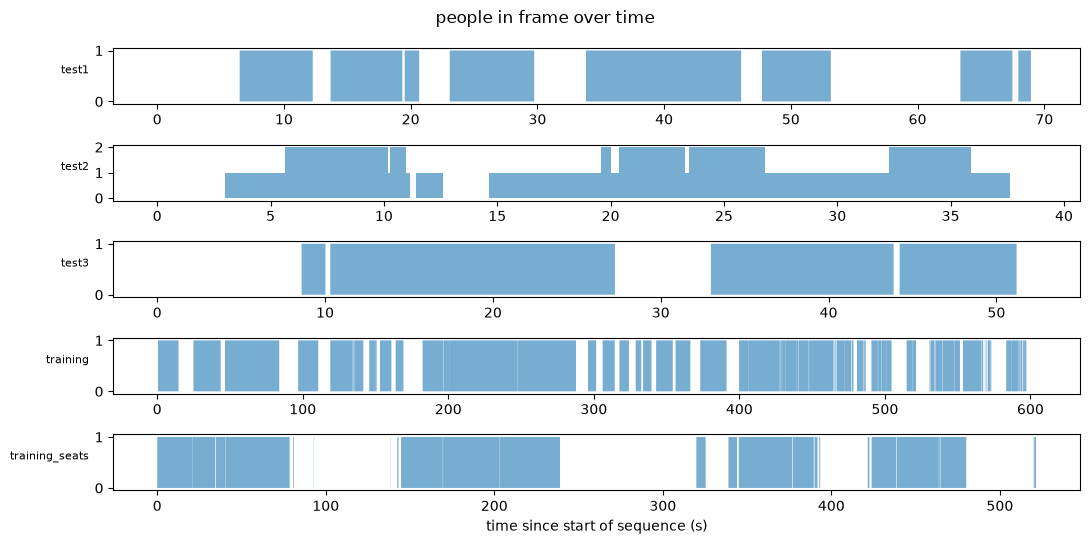

In [4]:
ann_names = [n for n, s in seqs.items() if 'label' in s]
fig, axes = plt.subplots(len(ann_names), 1, figsize=(11, 1.1 * len(ann_names)), sharex=False)
for ax, name in zip(axes, ann_names):
    s = seqs[name]
    t = s['times'] - s['times'][0]
    ax.fill_between(t, s['n_people'], step='post', alpha=0.6)
    ax.set_ylabel(name, rotation=0, ha='right', fontsize=8); ax.set_yticks(range(s['n_people'].max() + 1))
axes[-1].set_xlabel('time since start of sequence (s)')
fig.suptitle('people in frame over time'); plt.tight_layout(); plt.show()

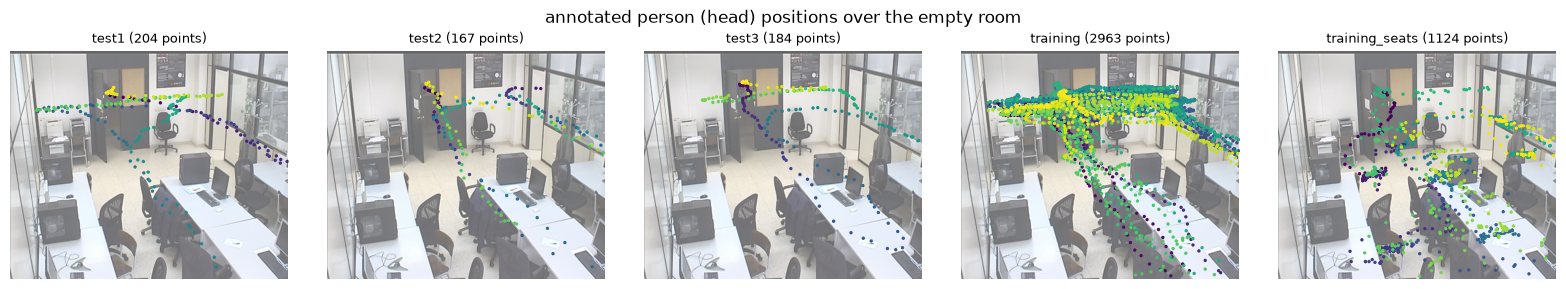

3 of 4642 annotated points lie outside the frame (person partly out of view): [[-206, 105], [-66, 546], [-53, 234]]


In [5]:
fig, axes = plt.subplots(1, len(ann_names), figsize=(3.2 * len(ann_names), 2.9))
with Image.open(seqs['training_bg']['files'][0]) as im:
    bg_rgb = np.asarray(im.convert('RGB'))
for ax, name in zip(axes, ann_names):
    xy = np.concatenate([p for p in seqs[name]['points'] if len(p)])
    ax.imshow(bg_rgb, alpha=0.6)
    ax.scatter(xy[:, 0], xy[:, 1], s=2, c=np.arange(len(xy)), cmap='viridis')
    ax.set_xlim(0, FULL_W); ax.set_ylim(FULL_H, 0)
    ax.set_title(f'{name} ({len(xy)} points)', fontsize=9); ax.axis('off')
fig.suptitle('annotated person (head) positions over the empty room'); plt.tight_layout(); plt.show()

xy_all = np.concatenate([p for n in ann_names for p in seqs[n]['points'] if len(p)])
outside = (xy_all[:, 0] < 0) | (xy_all[:, 0] >= FULL_W) | (xy_all[:, 1] < 0) | (xy_all[:, 1] >= FULL_H)
print(f'{outside.sum()} of {len(xy_all)} annotated points lie outside the frame (person partly out of view): '
      f'{xy_all[outside].tolist()}')

## 3. Images

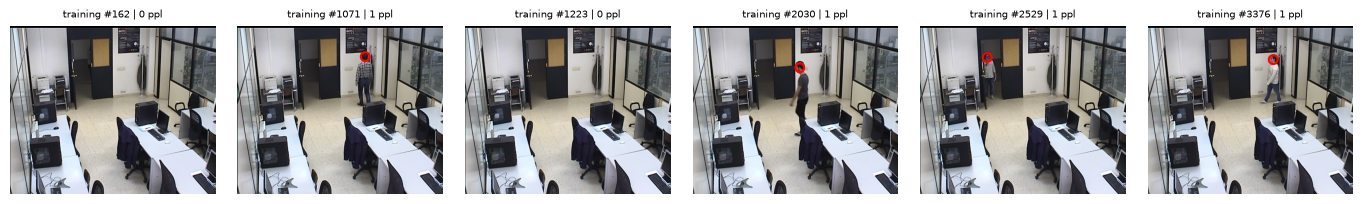

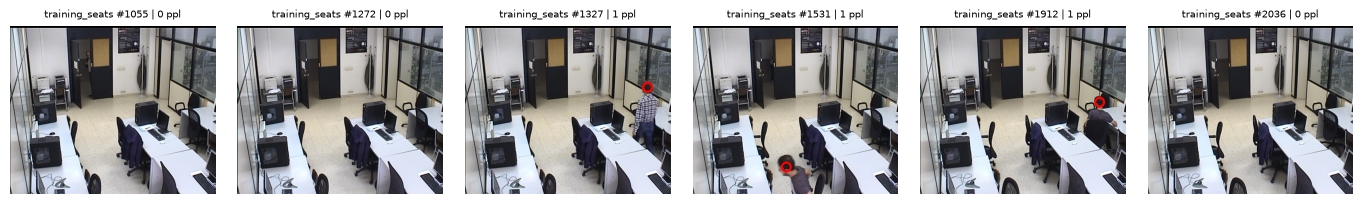

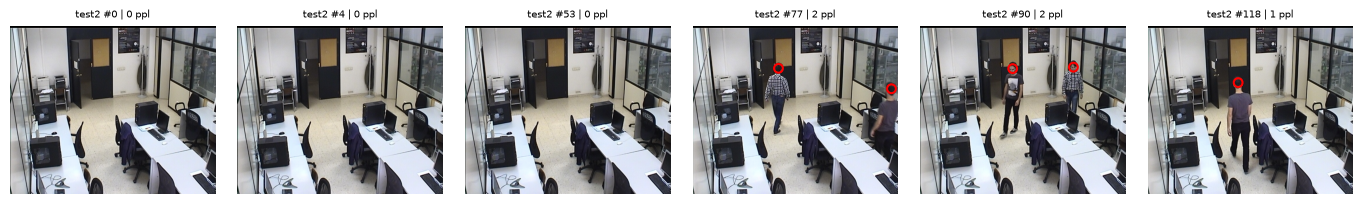

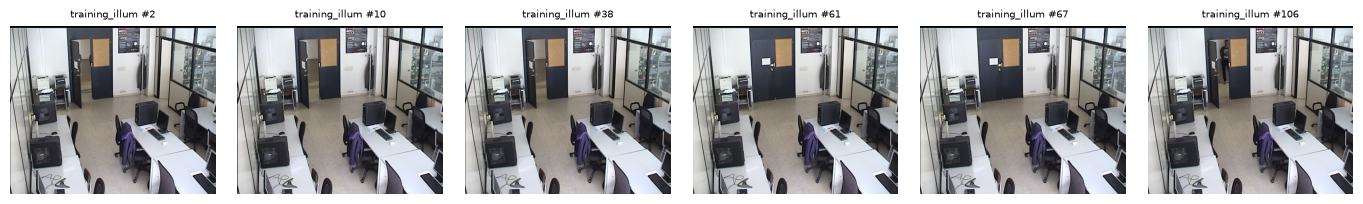

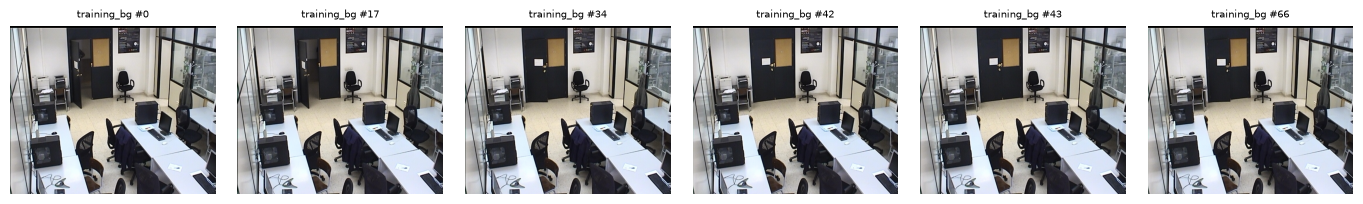

In [6]:
def show_frames(name, idx, ncols=6):
    s = seqs[name]
    nrows = int(np.ceil(len(idx) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(2.3 * ncols, 2.0 * nrows), squeeze=False)
    for ax in axes.flat:
        ax.axis('off')
    for ax, i in zip(axes.flat, idx):
        with Image.open(s['files'][i]) as im:
            ax.imshow(im.convert('RGB'))
        if 'points' in s and len(s['points'][i]):
            ax.scatter(*s['points'][i].T, s=40, facecolors='none', edgecolors='r', linewidths=1.5)
        lab = f" | {s['n_people'][i]} ppl" if 'n_people' in s else ''
        ax.set_title(f'{name} #{i}{lab}', fontsize=7)
    plt.tight_layout(); plt.show()

rng = np.random.default_rng(0)
for name in ['training', 'training_seats', 'test2', 'training_illum', 'training_bg']:
    n = len(seqs[name]['files'])
    show_frames(name, np.sort(rng.choice(n, 6, replace=False)))

### Load every frame at WISP resolution

All frames are decoded straight to grayscale at 1/4 scale (JPEG DCT scaling via `Image.draft`, which is much faster than full decoding) and resized to 160×120. This is the same input the Colab notebook uses, so results here carry over. The native 704×576 frame is 11:9, so the 4:3 resize stretches it slightly horizontally.

In [7]:
def load_gray(path):
    with Image.open(path) as im:
        im.draft('L', (W, H))
        return np.asarray(im.convert('L').resize((W, H), Image.BILINEAR), np.uint8)

t0 = time.time()
with ThreadPoolExecutor(8) as ex:
    for s in seqs.values():
        s['X'] = np.stack(list(ex.map(load_gray, s['files'])))
print(f"loaded {sum(len(s['X']) for s in seqs.values())} frames in {time.time() - t0:.1f}s, "
      f"{sum(s['X'].nbytes for s in seqs.values()) / 1e6:.0f} MB")

loaded 9332 frames in 9.3s, 179 MB


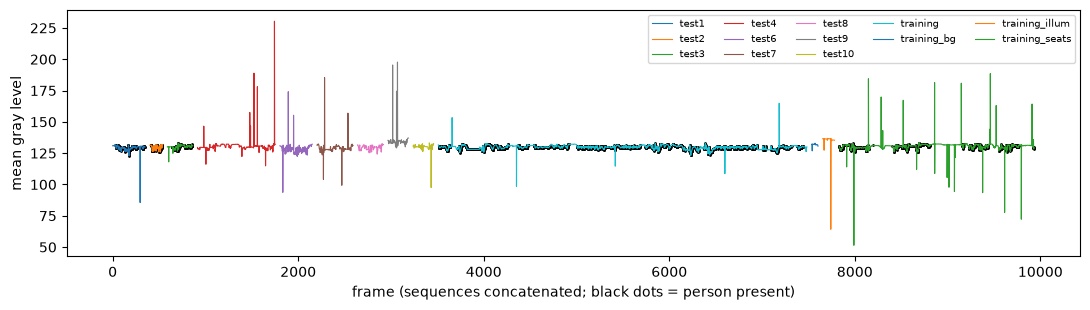

In [8]:
fig, ax = plt.subplots(figsize=(11, 3.2))
offset = 0
for name, s in seqs.items():
    m = s['X'].reshape(len(s['X']), -1).mean(1)
    x = offset + np.arange(len(m))
    ax.plot(x, m, lw=0.8, label=name)
    if 'label' in s:
        ax.scatter(x[s['label'] == 1], m[s['label'] == 1], s=1, c='k')
    offset += len(m) + 50
ax.set_xlabel('frame (sequences concatenated; black dots = person present)'); ax.set_ylabel('mean gray level')
ax.legend(ncol=5, fontsize=7); plt.tight_layout(); plt.show()

### Corrupted frames

The single-frame spikes above are not lighting changes: they are corrupted JPEGs in which blocks of the image are shifted and wrapped around. They are flagged here with a simple outlier rule (mean gray level more than 15 from the sequence median), which catches the obvious ones but may miss milder cases. `s['bad']` holds the mask. The annotators appear to have skipped these frames: they are labelled "no person" even when someone is clearly visible, so they are label noise as well as image noise. Drop them from training and evaluation.

sequence         flagged  labelled person
test1                  1                0
test2                  0                0
test3                  0                0
test4                  7                -
test6                  3                -
test7                  4                -
test8                  0                -
test9                  3                -
test10                 1                -
training               5                0
training_bg            0                -
training_illum         1                -
training_seats        18                0
total                 43


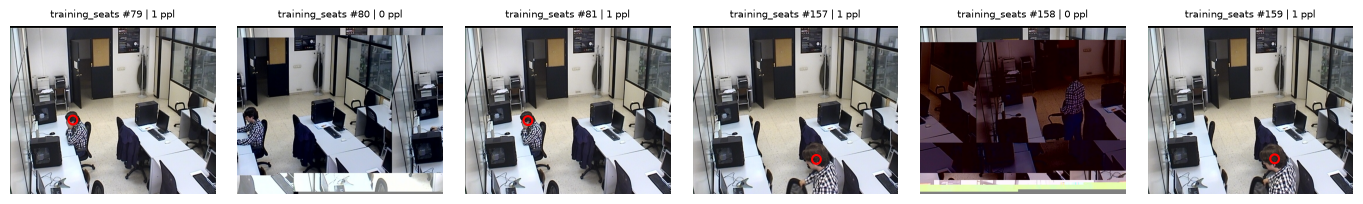

In [9]:
for s in seqs.values():
    m = s['X'].reshape(len(s['X']), -1).mean(1)
    s['bad'] = np.abs(m - np.median(m)) > 15
print(f"{'sequence':<16}{'flagged':>8}{'labelled person':>17}")
for name, s in seqs.items():
    lab = f"{s['label'][s['bad']].sum()}" if 'label' in s else '-'
    print(f"{name:<16}{s['bad'].sum():>8}{lab:>17}")
print(f"{'total':<16}{sum(s['bad'].sum() for s in seqs.values()):>8}")

name = 'training_seats'
show_frames(name, [j for i in np.flatnonzero(seqs[name]['bad'])[:2] for j in (i - 1, i, i + 1)])

## 4. What the WISP would send: thumbnails at EPC-sized budgets

Block-averaged thumbnails near the byte budgets of the Colab experiments (10, 40, 160, 640, 2560 bytes at 8 bits/pixel; grids must divide 160×120 exactly). A 4:3 grid of *w×h* pixels costs *w·h* bytes.

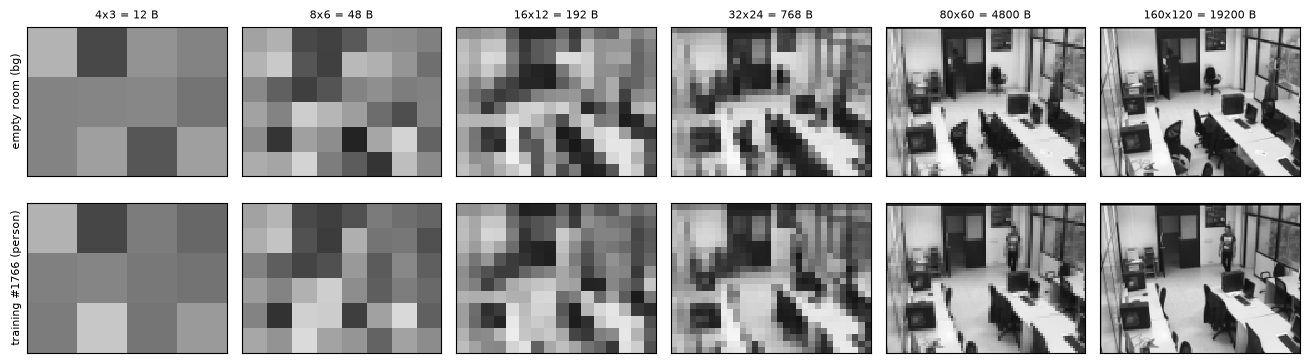

In [10]:
GRIDS = [(4, 3), (8, 6), (16, 12), (32, 24), (80, 60), (160, 120)]   # (w, h); bytes = w * h; each must divide 160x120

def thumb(X, w, h):
    # block-average a stack of 120x160 frames down to h x w (both divide the frame exactly)
    X = np.asarray(X, np.float32)
    return X.reshape(*X.shape[:-2], h, H // h, w, W // w).mean((-3, -1))

name = 'training'
i_pos = int(np.flatnonzero(seqs[name]['label'])[len(seqs[name]['label']) // 3])
frames = [('empty room (bg)', seqs['training_bg']['X'][0]), (f'{name} #{i_pos} (person)', seqs[name]['X'][i_pos])]
fig, axes = plt.subplots(2, len(GRIDS), figsize=(2.2 * len(GRIDS), 4))
for r, (title, x) in enumerate(frames):
    for c, (w, h) in enumerate(GRIDS):
        axes[r, c].imshow(thumb(x, w, h), cmap='gray', vmin=0, vmax=255, interpolation='nearest')
        axes[r, c].set_title(f'{w}x{h} = {w * h} B' if r == 0 else '', fontsize=8)
        axes[r, c].set_xticks([]); axes[r, c].set_yticks([])
    axes[r, 0].set_ylabel(title, fontsize=8)
plt.tight_layout(); plt.show()

## 5. Room-specific baselines: background model + a few pixels

The sensor never moves, so the server can learn what the empty room looks like. The simplest room-specific detector compares each thumbnail with a background thumbnail (median of `training_bg`) and thresholds the mean absolute difference. Below:

* **AUC per grid size** for this score on every annotated sequence (AUC is threshold-free, so the class imbalance noted above does not distort it).
* **Which pixels matter**: per-pixel AUC of |frame − background| on the training sequences, at 16×12.
* **Top-k pixels**: choose the k most informative pixels on `training` + `training_seats`, then score test sequences using only those k pixels, i.e. a k-byte payload.

These are deliberately naive lower bounds (no learning beyond pixel selection, no adaptation to lighting), meant to show how much room-specific structure there is.

In [11]:
def auc(score, y):
    # ROC AUC via the Mann-Whitney U statistic (ties get average ranks)
    score, y = np.asarray(score, np.float64), np.asarray(y).astype(bool)
    order = np.argsort(score, kind='mergesort')
    ranks = np.empty(len(score)); ranks[order] = np.arange(1, len(score) + 1)
    for v in np.unique(score[order][np.r_[False, np.diff(score[order]) == 0]]):   # average ties
        ranks[score == v] = ranks[score == v].mean()
    n1, n0 = y.sum(), (~y).sum()
    return (ranks[y].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)

BG = np.median(seqs['training_bg']['X'], axis=0)
TRAIN, TEST = ['training', 'training_seats'], ['test1', 'test2', 'test3']

print(f"{'grid':<10}{'bytes':>6}" + ''.join(f'{n:>16}' for n in TRAIN + TEST))
for w, h in GRIDS:
    bg_t = thumb(BG, w, h)
    row = [auc(np.abs(thumb(seqs[n]['X'], w, h) - bg_t).mean((1, 2)), seqs[n]['label']) for n in TRAIN + TEST]
    print(f"{f'{w}x{h}':<10}{w * h:>6}" + ''.join(f'{a:>16.3f}' for a in row))

grid       bytes        training  training_seats           test1           test2           test3
4x3           12           0.703           0.268           0.727           0.659           0.703
8x6           48           0.548           0.270           0.570           0.446           0.523
16x12        192           0.732           0.376           0.786           0.825           0.744
32x24        768           0.778           0.435           0.833           0.897           0.841
80x60       4800           0.810           0.479           0.857           0.905           0.864
160x120    19200           0.816           0.487           0.863           0.910           0.871


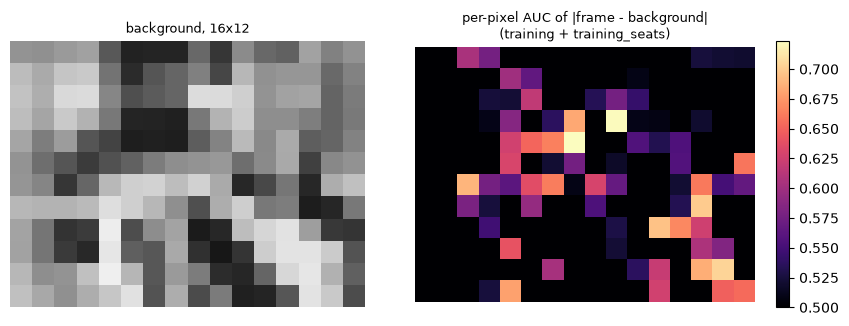

k pixels (bytes)       test1     test2     test3
1                      0.562     0.737     0.751
2                      0.821     0.697     0.690
4                      0.732     0.674     0.888
8                      0.690     0.803     0.888
16                     0.775     0.844     0.922
32                     0.851     0.847     0.933
64                     0.875     0.909     0.907
192                    0.786     0.825     0.744


In [12]:
w, h = 16, 12
bg_t = thumb(BG, w, h)
D_tr = np.concatenate([np.abs(thumb(seqs[n]['X'], w, h) - bg_t) for n in TRAIN]).reshape(-1, w * h)
y_tr = np.concatenate([seqs[n]['label'] for n in TRAIN])
pix_auc = np.array([auc(D_tr[:, j], y_tr) for j in range(w * h)])

fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
axes[0].imshow(bg_t, cmap='gray', vmin=0, vmax=255); axes[0].set_title(f'background, {w}x{h}', fontsize=9)
im = axes[1].imshow(pix_auc.reshape(h, w), cmap='magma', vmin=0.5, vmax=pix_auc.max())
axes[1].set_title('per-pixel AUC of |frame - background|\n(training + training_seats)', fontsize=9)
plt.colorbar(im, ax=axes[1]); [a.axis('off') for a in axes]; plt.tight_layout(); plt.show()

rank = np.argsort(-pix_auc)
KS = [1, 2, 4, 8, 16, 32, 64, w * h]
print(f"{'k pixels (bytes)':<18}" + ''.join(f'{n:>10}' for n in TEST))
for k in KS:
    sel = rank[:k]
    row = [auc(np.abs(thumb(seqs[n]['X'], w, h) - bg_t).reshape(-1, w * h)[:, sel].mean(1), seqs[n]['label']) for n in TEST]
    print(f'{k:<18}' + ''.join(f'{a:>10.3f}' for a in row))

How to read this:

* If a few selected pixels reach most of the full-thumbnail AUC, the room-specific "send a few pixels" idea has headroom: the camera (or the WISP MCU) could read out only those pixels, and the server could refine the choice over time.
* Pixels that are informative in training but not on the test sequences point to people standing in different places (compare with the position scatter in section 2); a learned, adaptive selection would have to cope with that.
* `training_illum` has no labels, but if the background score rises sharply there, the naive background model is mostly detecting lighting, and the server would need a lighting-invariant or continuously updated background.

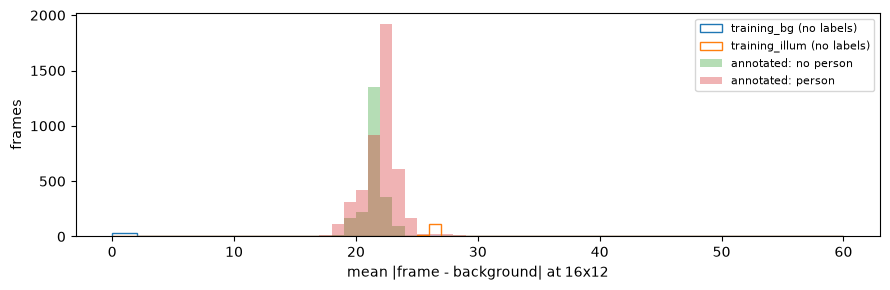

In [13]:
fig, ax = plt.subplots(figsize=(9, 3))
bins = np.linspace(0, 60, 61)
w, h = 16, 12
bg_t = thumb(BG, w, h)
for name in ['training_bg', 'training_illum']:
    ax.hist(np.abs(thumb(seqs[name]['X'], w, h) - bg_t).mean((1, 2)), bins, histtype='step', label=f'{name} (no labels)')
for lab, txt in [(0, 'no person'), (1, 'person')]:
    sc = np.concatenate([np.abs(thumb(seqs[n]['X'][seqs[n]['label'] == lab], w, h) - bg_t).mean((1, 2)) for n in TRAIN + TEST])
    ax.hist(sc, bins, histtype='stepfilled', alpha=0.35, label=f'annotated: {txt}')
ax.set_xlabel(f'mean |frame - background| at {w}x{h}'); ax.set_ylabel('frames'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

### Findings (as of the first run, 2026-10-22)

* **The fixed background works on the walking sequences but not on `training_seats`**: AUC is ~0.82–0.91 at full resolution for `training` and `test1`–`test3`, but *below 0.5* for `training_seats`. In that sequence the empty room no longer matches `training_bg` (the free-standing chair by the back wall is gone, other chairs and the door have moved), so "empty" looks more changed than "person sitting still". A room-specific encoder needs a background that **updates over time**, which fits the server-side online-learning idea.
* **Resolution helps, but not monotonically**: 8×6 scores worse than 4×3 with this naive score. Block averages at very low resolution are dominated by where block boundaries fall relative to the person.
* **A few chosen pixels beat the whole thumbnail**: with pixels chosen on the training sequences, 32–64 of the 16×12 pixels (32–64 bytes) reach AUC ~0.85–0.93 on the test sequences, above the full 192-pixel thumbnail (~0.75–0.83). Averaging in pixels where people never appear only adds noise, which is good evidence for the "capture only certain pixels" direction.
* **Data hygiene**: ~43 corrupted frames (labelled "no person" regardless of content), 3 annotated points outside the frame, irregular ~4–6 fps, and long label runs. Split by sequence.

## 6. Optional: export a compact training file

Writes every annotated sequence at 160×120 grayscale to `data/processed/piropo_conv2B_160x120.npz` (keys `X_<seq>` uint8 frames, `y_<seq>` person labels, `t_<seq>` unix timestamps, `bad_<seq>` corrupted-frame mask; `training_bg` has no `y_`), so training code (locally or in Colab via Drive) can skip JPEG decoding. Set `EXPORT = True` to write it.

In [14]:
EXPORT = False
if EXPORT:
    out = Path('..') / 'data' / 'processed' / 'piropo_conv2B_160x120.npz'
    out.parent.mkdir(parents=True, exist_ok=True)
    arrs = {}
    for name, s in seqs.items():
        if 'label' in s or name == 'training_bg':
            arrs[f'X_{name}'] = s['X']
            arrs[f't_{name}'] = s['times']
            arrs[f'bad_{name}'] = s['bad']
            if 'label' in s:
                arrs[f'y_{name}'] = s['label']
    np.savez_compressed(out, **arrs)
    print(f'wrote {out.resolve()} ({out.stat().st_size / 1e6:.1f} MB)')